<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week10_tugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Deskripsi Dataset

Dataset ini berisi **1.338 baris** data nasabah asuransi kesehatan dengan **7 kolom**, yang mencatat atribut personal nasabah beserta **biaya medis yang ditagihkan** (`charges`). Dataset berasal dari buku *Machine Learning with R* (Brett Lantz) dan banyak dipakai sebagai studi kasus regresi.

| Variabel | Tipe | Keterangan |
|---|---|---|
| `age` | Numerik (int) | Usia nasabah (tahun). Rentang 18–64 tahun. |
| `sex` | Kategorik | Jenis kelamin: `female`, `male`. |
| `bmi` | Numerik (float) | Body Mass Index, rasio berat/tinggi badan (kg/m²). Nilai normal 18.5–24.9. |
| `children` | Numerik (int) | Jumlah anak/tanggungan yang tercakup asuransi (0–5). |
| `smoker` | Kategorik | Status merokok: `yes`, `no`. |
| `region` | Kategorik | Wilayah tempat tinggal di Amerika Serikat: `northeast`, `northwest`, `southeast`, `southwest`. |
| `charges` | Numerik (float) | **Variabel target** — biaya medis personal yang ditagihkan (USD). |

**Tujuan analisis:** membangun model *multiple linear regression* untuk memprediksi `charges` berdasarkan enam variabel bebas (`age`, `sex`, `bmi`, `children`, `smoker`, `region`), lalu mengukur seberapa baik model tersebut bekerja pada data yang belum pernah dilihat.

### 2. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Tampilan
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)
np.random.seed(42)

### 3. Memuat Dataset

Di Google Colab, jalankan cell di bawah. Jika `insurance.csv` belum ada di direktori kerja, file akan diminta untuk di-upload secara otomatis.

In [2]:
try:
    df = pd.read_csv('insurance.csv')
except FileNotFoundError:
    from google.colab import files
    files.upload()          # pilih insurance.csv dari komputer
    df = pd.read_csv('insurance.csv')

print('Ukuran dataset:', df.shape, '-> (baris, kolom)')
df.head()

Ukuran dataset: (1338, 7) -> (baris, kolom)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Struktur dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
# Statistik deskriptif variabel numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [5]:
# Statistik deskriptif variabel kategorik
df.describe(include='object').T

,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


### 4. Pemeriksaan Kualitas Data

Sebelum pemodelan, dicek dua hal yang paling sering menjadi sumber masalah: **nilai hilang (missing value)** dan **data duplikat**.

In [6]:
print('Nilai hilang per kolom:')
print(df.isnull().sum())

print('\nJumlah baris duplikat :', df.duplicated().sum())
print('Jumlah nilai unik     :')
print(df.nunique())

Nilai hilang per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris duplikat : 1
Jumlah nilai unik     :
age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64


**Catatan:** tidak ada nilai hilang. Ditemukan **1 baris duplikat** (0,07% dari data). Baris ini dibiarkan karena jumlahnya sangat kecil sehingga tidak mengubah kesimpulan model secara material — namun pada analisis yang lebih ketat, baris tersebut sebaiknya dihapus (`df.drop_duplicates()`).

#### Deteksi outlier secara kasar (metode IQR)

```text
Q1 - 1.5*IQR  ...  Q3 + 1.5*IQR
```

In [7]:
q1, q3 = df['charges'].quantile([0.25, 0.75])
iqr = q3 - q1
batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier = df[(df['charges'] < batas_bawah) | (df['charges'] > batas_atas)]
print(f'Batas bawah : {batas_bawah:,.2f}')
print(f'Batas atas  : {batas_atas:,.2f}')
print(f'Jumlah outlier charges: {len(outlier)} baris ({len(outlier)/len(df)*100:.1f}%)')

Batas bawah : -13,109.15
Batas atas  : 34,489.35
Jumlah outlier charges: 139 baris (10.4%)


Outlier tidak dihapus karena **bukan kesalahan input**, melainkan nasabah dengan biaya medis yang memang sangat tinggi (umumnya perokok dengan BMI tinggi). Menghapusnya justru menghilangkan informasi penting — konsekuensinya, error model pada segmen ini akan relatif besar.

### 5. Exploratory Data Analysis (EDA)

#### 5.1 Distribusi variabel target `charges`

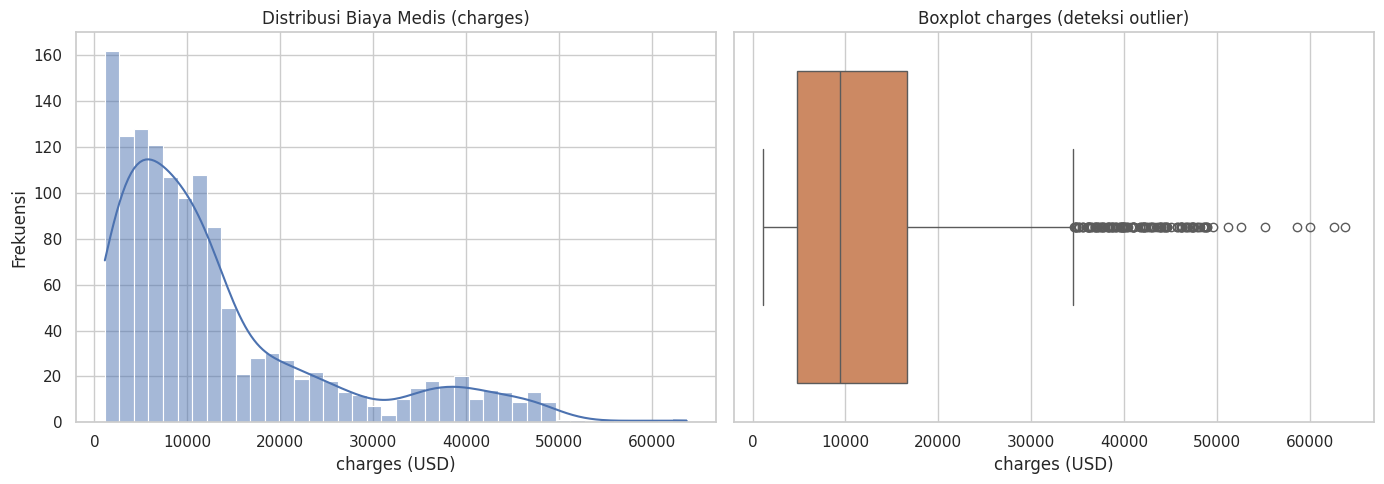

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], bins=40, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Distribusi Biaya Medis (charges)')
axes[0].set_xlabel('charges (USD)')
axes[0].set_ylabel('Frekuensi')

sns.boxplot(x=df['charges'], ax=axes[1], color='#DD8452')
axes[1].set_title('Boxplot charges (deteksi outlier)')
axes[1].set_xlabel('charges (USD)')

plt.tight_layout()
plt.show()

Distribusi `charges` **menceng ke kanan (right-skewed)**: sebagian besar nasabah berbiaya rendah–menengah, tetapi ada ekor panjang ke arah biaya sangat tinggi (maksimum ±63.770 USD). Terlihat juga pola *bimodal* — ada dua kelompok biaya yang terpisah, yang nanti terbukti berkaitan dengan status merokok.

#### 5.2 Distribusi variabel kategorik

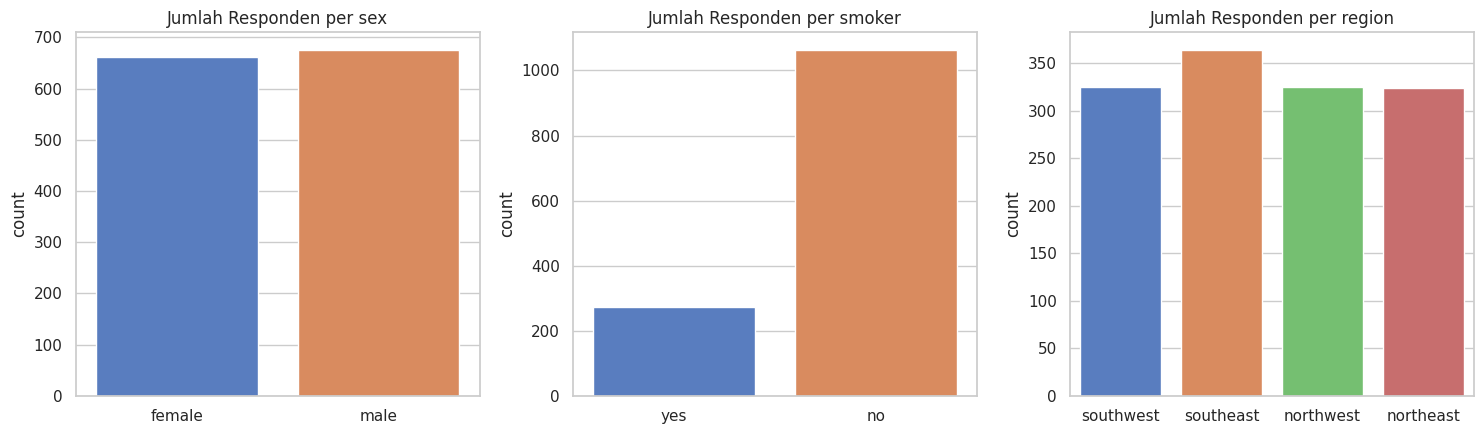

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, ['sex', 'smoker', 'region']):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=ax, palette='muted')
    ax.set_title(f'Jumlah Responden per {col}')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

Komposisi data cukup seimbang untuk `sex` dan `region`, tetapi **tidak seimbang untuk `smoker`**: hanya ±20% nasabah berstatus perokok. Karena itu, interpretasi koefisien `smoker` perlu hati-hati, meskipun efeknya sangat besar.

#### 5.3 Hubungan `age` dan `bmi` terhadap `charges`

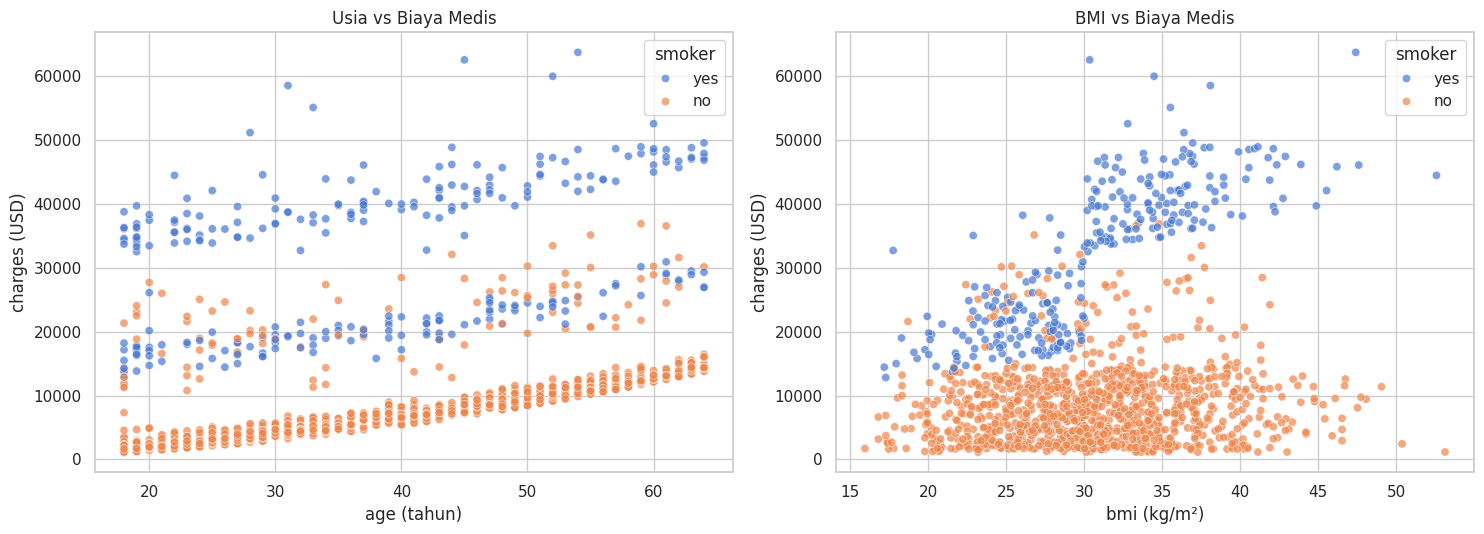

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[0])
axes[0].set_title('Usia vs Biaya Medis')
axes[0].set_xlabel('age (tahun)')
axes[0].set_ylabel('charges (USD)')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].set_title('BMI vs Biaya Medis')
axes[1].set_xlabel('bmi (kg/m²)')
axes[1].set_ylabel('charges (USD)')

plt.tight_layout()
plt.show()

Dua temuan penting:

1. **`smoker` memisahkan data menjadi dua "pita" biaya.** Perokok (biru) konsisten berada jauh di atas non-perokok (oranye) pada usia maupun BMI yang sama.
2. **`age` berhubungan positif dan hampir linier** dengan `charges`, sedangkan `bmi` hanya berpengaruh kuat pada kelompok perokok (terlihat dari pita biru yang menanjak tajam setelah BMI ±30). Ini mengindikasikan adanya **interaksi `smoker` × `bmi`** yang tidak dapat ditangkap oleh regresi linier tanpa fitur interaksi.

#### 5.4 Encoding variabel kategorik

Regresi linier hanya menerima input numerik, sehingga:

* `sex` dan `smoker` (biner) → **label encoding** (0/1).
* `region` (4 kategori, nominal) → **one-hot encoding** dengan `drop_first=True` untuk menghindari *dummy variable trap* (multikolinearitas sempurna).

In [11]:
df_encoded = df.copy()

df_encoded['sex']    = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})

df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True, dtype=int)

df_encoded.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


#### 5.5 Matriks korelasi

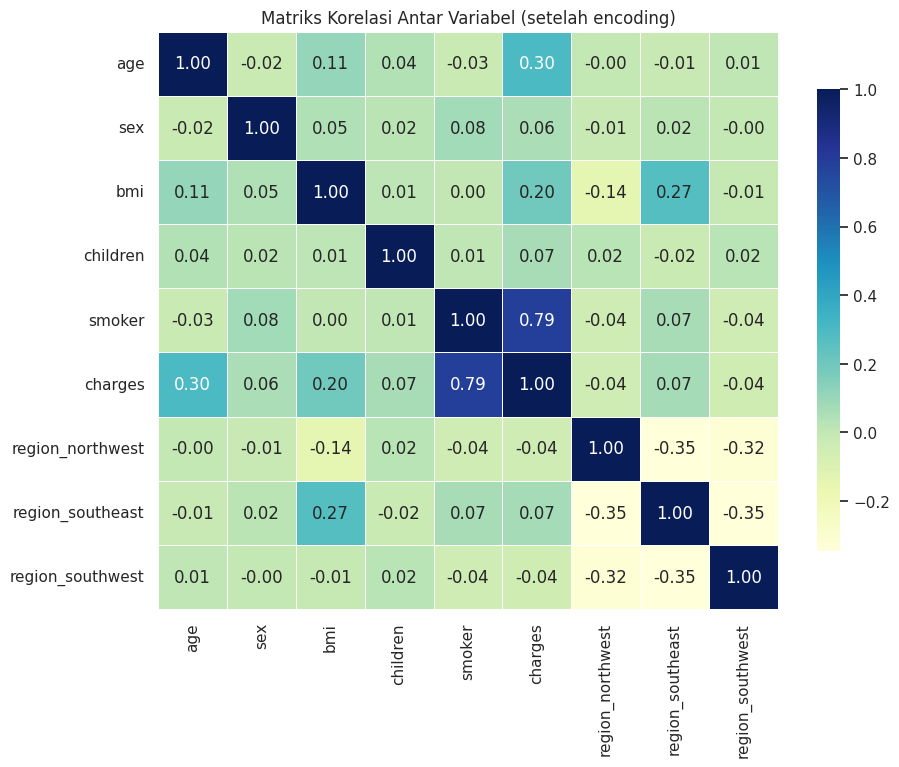

In [12]:
plt.figure(figsize=(10, 7.5))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='YlGnBu',
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriks Korelasi Antar Variabel (setelah encoding)')
plt.show()

In [13]:
# Urutan korelasi setiap fitur terhadap target
df_encoded.corr()['charges'].sort_values(ascending=False)

,charges
charges,1.000000
smoker,0.787251
age,0.299008
bmi,0.198341
region_southeast,0.073982
children,0.067998
sex,0.057292
region_northwest,-0.039905
region_southwest,-0.043210


`smoker` memiliki korelasi tertinggi terhadap `charges` (**r ≈ 0,79**), diikuti `age` (≈ 0,30) dan `bmi` (≈ 0,20). `sex` dan `region` hampir tidak berkorelasi (|r| < 0,08) — jadi wajar bila kontribusinya kecil, tetapi tetap dipertahankan karena secara teori relevan dan tidak mengganggu model.

Perhatikan juga tidak ada korelasi antar-fitur yang tinggi (semua < 0,31), sehingga **tidak ada masalah multikolinearitas** yang serius.

### 6. Persiapan Data untuk Pemodelan

**Definisi variabel:**
* **Variabel bebas (X):** `age`, `sex`, `bmi`, `children`, `smoker`, `region_northwest`, `region_southeast`, `region_southwest` (8 fitur).
* **Variabel target (y):** `charges`.

**Proporsi split:** 80% data latih (1.070 baris) dan 20% data uji (268 baris). Proporsi ini standar untuk dataset berukuran ±1.300 baris: cukup data untuk melatih, dan cukup data untuk evaluasi yang stabil. `random_state=42` dipakai agar hasil **reproducible**.

In [14]:
# Variabel bebas dan target
X = df_encoded.drop(columns='charges')
y = df_encoded['charges']

print('Fitur yang digunakan:', list(X.columns))
print('Jumlah fitur        :', X.shape[1])

Fitur yang digunakan: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']
Jumlah fitur        : 8


In [15]:
# Split data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Data latih :', X_train.shape, '->', f'{len(X_train)/len(X)*100:.0f}% data')
print('Data uji   :', X_test.shape, '->', f'{len(X_test)/len(X)*100:.0f}% data')

Data latih : (1070, 8) -> 80% data
Data uji   : (268, 8) -> 20% data


#### Feature scaling

Regresi linier **secara matematis tidak membutuhkan** scaling (koefisien akan menyesuaikan skala masing-masing fitur). Namun scaling tetap dilakukan karena:

1. Membuat **perbandingan besarnya pengaruh antar fitur** menjadi apple-to-apple (semua fitur dalam satuan standar deviasi).
2. Menjaga konsistensi pipeline bila nanti model dibandingkan dengan algoritma berbasis jarak seperti **SVR** (bagian bonus).

Metode: **StandardScaler** (z-score), dengan `fit` hanya pada data latih agar tidak terjadi *data leakage*.

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # fit + transform pada data latih
X_test_scaled  = scaler.transform(X_test)        # HANYA transform pada data uji

pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[['mean', 'std', 'min', 'max']]

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
mean,-1.992176e-16,-6.308557e-17,-4.648410e-17,-2.324205e-17,2.988264e-17,-4.648410e-17,-3.320293e-17,7.304645e-17
std,1.000468e+00,1.000468e+00,1.000468e+00,1.000468e+00,1.000468e+00,1.000468e+00,1.000468e+00,1.000468e+00
min,-1.518194e+00,-1.024602e+00,-2.417060e+00,-9.111921e-01,-5.087470e-01,-5.607997e-01,-5.996611e-01,-5.723141e-01
max,1.751782e+00,9.759891e-01,3.736342e+00,3.202629e+00,1.965613e+00,1.783168e+00,1.667609e+00,1.747292e+00


### 7. Membangun Model Multiple Linear Regression

Model yang dibentuk:

$$\hat{y} = \beta_0 + \beta_1 x_{age} + \beta_2 x_{sex} + \beta_3 x_{bmi} + \beta_4 x_{children} + \beta_5 x_{smoker} + \beta_6 x_{region}$$

dengan `charges` sebagai $\hat{y}$ dan koefisien $\beta$ diestimasi menggunakan **Ordinary Least Squares (OLS)**, yaitu meminimalkan jumlah kuadrat residual.

In [17]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print('Model berhasil dilatih.')
print(f'Intercept (beta_0): {model.intercept_:,.2f}')

Model berhasil dilatih.
Intercept (beta_0): 13,346.09


In [18]:
# Tabel koefisien (data sudah terstandarisasi -> koefisien = perubahan charges
# per kenaikan 1 standar deviasi fitur)
koefisien = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_
})
koefisien['|Koefisien|'] = koefisien['Koefisien'].abs()
koefisien = koefisien.sort_values('|Koefisien|', ascending=False).drop(columns='|Koefisien|')
koefisien.round(2)

,Fitur,Koefisien
4,smoker,9558.48
0,age,3614.98
2,bmi,2036.23
3,children,516.89
7,region_southwest,-349.11
6,region_southeast,-290.16
5,region_northwest,-158.14
1,sex,-9.29


**Interpretasi koefisien (data terstandarisasi):**

| Fitur | Koefisien | Arti praktis |
|---|---|---|
| `smoker` | ≈ **+9.558** | Menjadi perokok menaikkan biaya ±9.558 USD *pada variabel lain dianggap konstan* — efek terbesar. |
| `age` | ≈ **+3.615** | Setiap kenaikan 1 standar deviasi usia (±14 tahun) menaikkan biaya ±3.615 USD. |
| `bmi` | ≈ **+2.036** | Setiap kenaikan 1 SD BMI (±6,1 kg/m²) menaikkan biaya ±2.036 USD. |
| `children` | ≈ **+517** | Setiap tambahan 1 SD jumlah anak menaikkan biaya ±517 USD. |
| `sex` | ≈ **−9** | Praktis **nol** → jenis kelamin tidak berpengaruh setelah faktor lain dikontrol. |
| `region_*` | −158 s/d −349 | Perbedaan antar wilayah sangat kecil dibandingkan efek `smoker`. |

Karena datanya terstandarisasi, **besar koefisien bisa langsung dibandingkan** untuk menentukan fitur mana yang paling berpengaruh.

### 8. Prediksi pada Data Uji

Model yang sudah dilatih dipakai untuk memprediksi `charges` pada data uji (data yang tidak pernah dilihat model saat training).

In [19]:
# Prediksi
y_train_pred = model.predict(X_train_scaled)
y_test_pred  = model.predict(X_test_scaled)

# Bandingkan 10 prediksi pertama dengan nilai aktualnya
hasil_prediksi = pd.DataFrame({
    'Aktual (USD)': y_test.values[:10],
    'Prediksi (USD)': y_test_pred[:10].round(2)
})
hasil_prediksi['Selisih (USD)'] = (hasil_prediksi['Aktual (USD)'] - hasil_prediksi['Prediksi (USD)']).round(2)
hasil_prediksi

,Aktual (USD),Prediksi (USD),Selisih (USD)
0,9095.06825,8969.55,125.52
1,5272.17580,7068.75,-1796.57
2,29330.98315,36858.41,-7527.43
3,9301.89355,9454.68,-152.79
4,33750.29180,26973.17,6777.12
5,4536.25900,10864.11,-6327.85
6,2117.33885,170.28,1947.06
7,14210.53595,16903.45,-2692.91
8,3732.62510,1092.43,2640.20
9,10264.44210,11218.34,-953.90


### 9. Evaluasi Model

Metrik yang digunakan:

* **R² (R-squared)** — proporsi variansi `charges` yang berhasil dijelaskan model. Rentang 0–1, semakin tinggi semakin baik.
* **MSE (Mean Squared Error)** — rata-rata kuadrat error. Sensitif terhadap error besar.
* **RMSE (Root MSE)** — akar dari MSE, satuannya sama dengan target (USD) sehingga mudah ditafsirkan.
* **MAE (Mean Absolute Error)** — rata-rata error absolut, lebih tahan terhadap outlier.

In [20]:
def evaluasi(y_true, y_pred, nama_data):
    return {
        'Data': nama_data,
        'R-squared': r2_score(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
    }

hasil = pd.DataFrame([
    evaluasi(y_train, y_train_pred, 'Train'),
    evaluasi(y_test,  y_test_pred,  'Test'),
])
hasil

,Data,R-squared,MSE,RMSE,MAE
0,Train,0.741726,3.727768e+07,6105.545160,4208.234572
1,Test,0.783593,3.359692e+07,5796.284659,4181.194474


In [21]:
for _, row in hasil.iterrows():
    print(f"{row['Data']:5s} | R² = {row['R-squared']:.4f} | "
          f"MSE = {row['MSE']:,.2f} | RMSE = {row['RMSE']:,.2f} | MAE = {row['MAE']:,.2f}")

print()
print(f"Rata-rata charges (keseluruhan data): {y.mean():,.2f} USD")
print(f"MAE data uji = {hasil.loc[1, 'MAE']:,.2f} USD "
      f"(±{hasil.loc[1, 'MAE'] / y.mean() * 100:.1f}% dari rata-rata charges)")

Train | R² = 0.7417 | MSE = 37,277,681.70 | RMSE = 6,105.55 | MAE = 4,208.23
Test  | R² = 0.7836 | MSE = 33,596,915.85 | RMSE = 5,796.28 | MAE = 4,181.19

Rata-rata charges (keseluruhan data): 13,270.42 USD
MAE data uji = 4,181.19 USD (±31.5% dari rata-rata charges)


### 10. Visualisasi Hasil Model

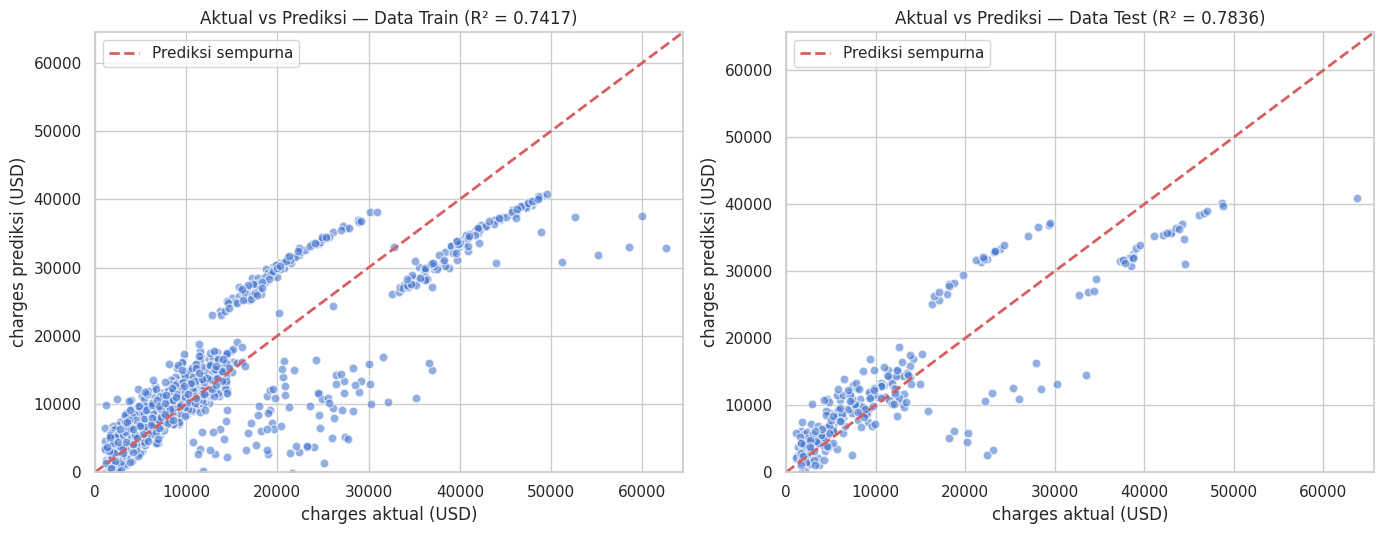

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, y_true, y_pred, nama in zip(
        axes,
        [y_train, y_test],
        [y_train_pred, y_test_pred],
        ['Train', 'Test']):
    ax.scatter(y_true, y_pred, alpha=0.6, edgecolor='white', s=40)
    batas = [0, max(y_true.max(), y_pred.max()) * 1.03]
    ax.plot(batas, batas, 'r--', lw=2, label='Prediksi sempurna')
    ax.set_xlim(batas)
    ax.set_ylim(batas)
    ax.set_xlabel('charges aktual (USD)')
    ax.set_ylabel('charges prediksi (USD)')
    ax.set_title(f'Aktual vs Prediksi — Data {nama} (R² = {r2_score(y_true, y_pred):.4f})')
    ax.legend()

plt.tight_layout()
plt.show()

Titik-titik mengikuti garis merah (prediksi sempurna) pada rentang biaya rendah–menengah, tetapi **menyimpang di biaya tinggi**: model cenderung **underestimate** untuk nasabah berbiaya sangat tinggi. Ini konsekuensi wajar dari model linier yang tidak memiliki fitur interaksi.

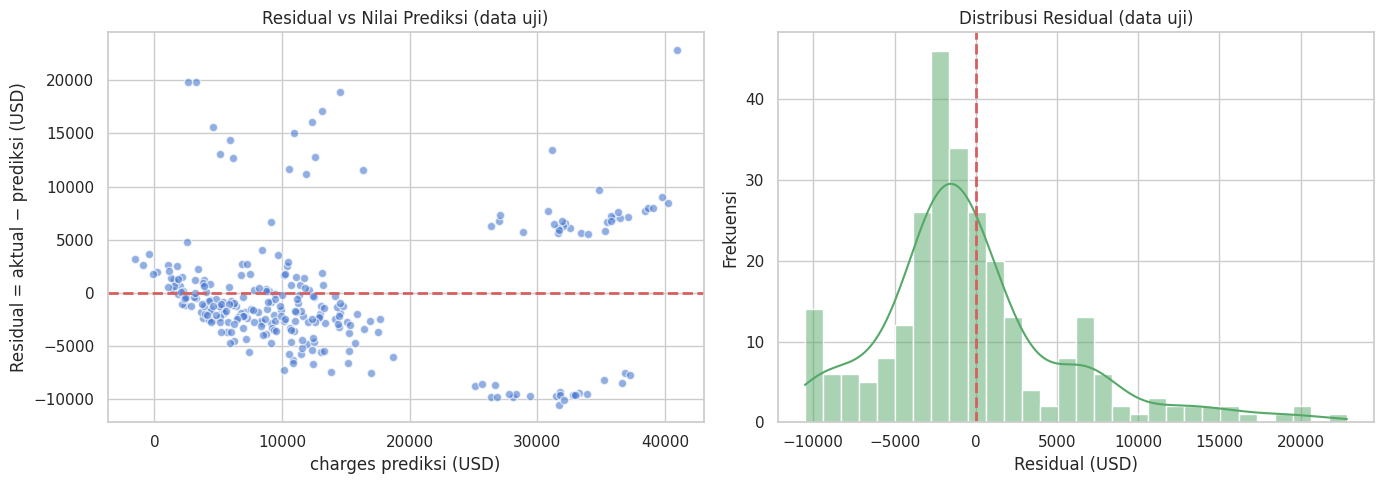

In [23]:
residual = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_pred, residual, alpha=0.6, edgecolor='white')
axes[0].axhline(0, color='r', linestyle='--', lw=2)
axes[0].set_xlabel('charges prediksi (USD)')
axes[0].set_ylabel('Residual = aktual − prediksi (USD)')
axes[0].set_title('Residual vs Nilai Prediksi (data uji)')

sns.histplot(residual, bins=30, kde=True, ax=axes[1], color='#55A868')
axes[1].axvline(0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Residual (USD)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Residual (data uji)')

plt.tight_layout()
plt.show()

In [24]:
print('Statistik residual data uji:')
print(residual.describe().round(2))
print(f'\nRata-rata residual : {residual.mean():,.2f} USD')
print(f'Std residual       : {residual.std():,.2f} USD')

Statistik residual data uji:
count      268.00
mean      -219.24
std       5802.97
min     -10512.58
25%      -2941.14
50%      -1242.93
75%       1560.80
max      22850.14
Name: charges, dtype: float64

Rata-rata residual : -219.24 USD
Std residual       : 5,802.97 USD


Residual menyebar di sekitar nol (rata-rata ≈ −219 USD, mendekati 0) yang berarti model **tidak bias sistematis**. Namun sebarannya **melebar saat nilai prediksi membesar** (pola corong/*heteroskedastisitas*) — model kurang akurat untuk nasabah berbiaya tinggi. Distribusi residual juga sedikit menceng ke kanan akibat beberapa error besar.

### 11. Analisis Hasil

**Ringkasan performa model:**

| Metrik | Data Latih | Data Uji | Selisih (Train − Test) |
|---|---|---|---|
| R² | 0,7417 | **0,7836** | −0,0419 |
| MSE | 37.277.681,70 | 33.596.915,85 | +3.680.765,85 |
| RMSE | 6.105,55 | 5.796,28 | +309,27 |
| MAE | 4.208,23 | 4.181,19 | +27,04 |

**Poin-poin analisis:**

1. **Model cukup baik, tapi belum sempurna.** R² data uji = **0,7836** berarti model menjelaskan **±78,4%** variansi biaya medis; sisanya 21,6% dijelaskan faktor lain yang tidak ada di dataset (riwayat penyakit, jenis polis, lokasi detail, gaya hidup lain).

2. **Tidak terjadi overfitting.** R² data latih (0,7417) justru **lebih rendah** daripada data uji (0,7836), dengan selisih sangat kecil. Artinya model **stabil dan mampu generalisasi** — bukan menghafal data latih. (Data uji yang sedikit lebih tinggi terjadi karena komposisi 268 baris data uji kebetulan sedikit "lebih mudah" diprediksi.)

3. **Error rata-rata ±4.181 USD (MAE)**, atau ±31,5% dari rata-rata biaya medis (13.270 USD). Untuk prediksi biaya asuransi, angka ini tergolong wajar — tetapi secara praktis masih cukup besar untuk penetapan premi. RMSE (5.796) > MAE (4.181) menandakan **ada beberapa error besar**, konsisten dengan adanya nasabah berbiaya ekstrem yang sulit diprediksi.

4. **`smoker` adalah prediktor dominan** (koefisien +9.558 pada skala terstandar), jauh di atas `age` (+3.615) dan `bmi` (+2.036). `sex` hampir nol (−9) dan `region` sangat kecil. Ini sejalan dengan korelasi (0,79 / 0,30 / 0,20) dan pola scatter plot sebelumnya.

5. **Keterbatasan model linier.** Scatter plot menunjukkan efek `bmi` hanya kuat pada perokok — sebuah **interaksi `smoker` × `bmi`**. Regresi linier tanpa fitur interaksi tidak bisa menangkapnya, sehingga model cenderung *underestimate* pada perokok dengan BMI tinggi. Ini adalah sumber error terbesar, terlihat dari residual yang melebar di nilai prediksi tinggi.

**Rekomendasi perbaikan:**
* Tambahkan fitur interaksi `smoker × bmi` (dan mungkin `age × bmi`).
* Transformasi target `log(charges)` karena distribusinya right-skewed.
* Gunakan model non-linier seperti **SVR (RBF)**, Random Forest, atau Gradient Boosting — lihat bagian bonus di bawah.

### 12. Kesimpulan

1. Model multiple linear regression dengan 8 fitur (6 variabel asli setelah encoding) menghasilkan **R² = 0,7836, MSE = 33.596.915,85, RMSE = 5.796,28, dan MAE = 4.181,19** pada data uji.
2. Performa data latih dan data uji hampir identik → model **tidak overfitting** dan cukup stabil.
3. **Status merokok** adalah faktor paling menentukan biaya medis, diikuti usia dan BMI; jenis kelamin dan wilayah hampir tidak berpengaruh.
4. Karena hubungan antar variabel tidak sepenuhnya linier, model linier masih menyisakan error cukup besar pada nasabah berbiaya tinggi — sehingga model non-linier berpotensi memberi hasil lebih baik.

---
##Perbandingan dengan Support Vector Regression (SVR)

Instruksi praktikum juga menyinggung **SVR**. Karena data sudah terstandarisasi, SVR dengan kernel RBF bisa dilatih langsung. Hyperparameter dicari dengan `GridSearchCV` (3-fold cross-validation) pada data latih saja.

In [25]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [1000, 10000, 100000],
    'gamma': [0.01, 0.1, 0.5],
    'epsilon': [100, 1000, 5000]
}

grid = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=3,
                    scoring='neg_root_mean_squared_error', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('Parameter terbaik:', grid.best_params_)
print(f'RMSE CV terbaik   : {-grid.best_score_:,.2f} USD')

Parameter terbaik: {'C': 100000, 'epsilon': 1000, 'gamma': 0.1}
RMSE CV terbaik   : 4,920.28 USD


In [26]:
svr = grid.best_estimator_
y_svr_pred = svr.predict(X_test_scaled)

perbandingan = pd.DataFrame([
    evaluasi(y_test, y_test_pred, 'Linear Regression'),
    evaluasi(y_test, y_svr_pred, 'SVR (RBF)'),
]).set_index('Data')
perbandingan

,R-squared,MSE,RMSE,MAE
Data,,,,
Linear Regression,0.783593,3.359692e+07,5796.284659,4181.194474
SVR (RBF),0.864826,2.098559e+07,4581.002678,2281.472423


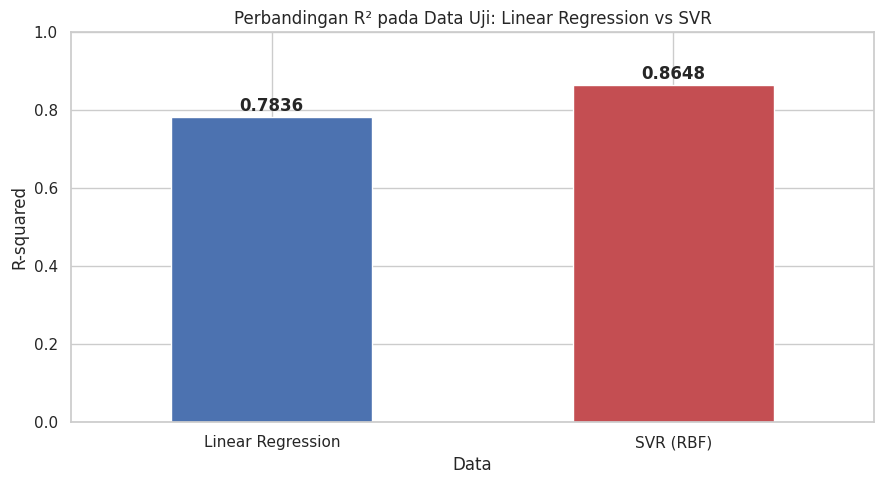

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
perbandingan['R-squared'].plot(kind='bar', ax=ax, color=['#4C72B0', '#C44E52'], width=0.5)
ax.set_title('Perbandingan R² pada Data Uji: Linear Regression vs SVR')
ax.set_ylabel('R-squared')
ax.set_ylim(0, 1)
ax.set_xticklabels(perbandingan.index, rotation=0)
for i, v in enumerate(perbandingan['R-squared']):
    ax.text(i, v + 0.015, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Hasil:** SVR (RBF) mencapai **R² ≈ 0,865** dengan **MAE ≈ 2.281 USD** — jauh lebih baik daripada regresi linier (R² 0,784; MAE 4.181 USD). Perbaikan ini masuk akal karena kernel RBF mampu menangkap **hubungan non-linier dan interaksi antar fitur** (terutama `smoker` × `bmi`) yang tidak dapat direpresentasikan oleh model linier.

Kelebihan regresi linier tetap ada: **mudah diinterpretasikan** (koefisien tiap fitur jelas), cepat dilatih, dan menjadi *baseline* yang baik sebelum mencoba model yang lebih kompleks.

---
### Referensi

* Lantz, B. (2019). *Machine Learning with R* (3rd ed.). Packt Publishing. — sumber dataset Medical Cost Personal.
* Scikit-learn documentation: [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [`SVR`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html), [metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).
* Dataset: [Medical Cost Personal Datasets — Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance).